In [1]:
import Pyro4
import numpy as np
import matplotlib.pyplot as plt
import threading
import time
import os, ntpath
import sys, shutil
from pathlib import Path
from lmfit import Model, create_params
from lmfit.models import LinearModel, LorentzianModel, GaussianModel, VoigtModel, PolynomialModel, ConstantModel

from scipy.fft import fft, ifft, fftfreq

def my_find_nearest(ar,target):
    index = (np.abs(ar - target)).argmin()
    return index


def exponential(t, tau, A):
    return np.exp(-t/tau)*A

def power_law(t, lambd, t0, A):
    return A*t**(-lambd)

def power_law_times_exp(t, tau, t0,lambd, A):
    return A*(t/t0)**(-lambd)*np.exp(-t/tau)

exp_model = Model(exponential, independent_vars=['t'], param_names = ['tau','A'])
powerlaw_model = Model(power_law, independent_vars=['t'], param_names = ['lambd','t0','A'])
powerlaw_exponential_model = Model(power_law_times_exp, independent_vars=['t'], param_names = ['tau', 't0','lambd', 'A'])

## SET UP CLIENT SERVER CONNECTION
Pyro4.config.SERIALIZER = "pickle"
Pyro4.config.SERIALIZERS_ACCEPTED = {"pickle"}
Pyro4.config.SERVERTYPE = "thread"          
Pyro4.config.THREADPOOL_SIZE = 40           
Pyro4.config.THREADPOOL_SIZE_MIN = 4

URI = "PYRO:Analysis_g13@127.0.0.1:9097"
# URI = "PYRO:Analysis_g13@g13-sspd.dhcp-int.phys.ethz.ch:9098"
try:
    stop_logs.set()
except:
    pass

def g2izer(tau, hist, t_acq_tot_s, n_new_bins=None, ref_range_s=None,verbose = False):
    if n_new_bins is not None and isinstance(n_new_bins, int):
        if verbose: 
            print(f"Rebinning from {len(tau):d} to {n_new_bins:d}")
        tau_rebin, h_rebin = re_bin(tau*1e9,hist, int(n_new_bins))
        tau_rebin = (tau_rebin).astype(float)*1e-9

        # Apply biased norm (acceptance)
        # g2_biased_norm = t_acq_tot_s - tau_rebin
        # h_rebin = h_rebin.astype(float)/g2_biased_norm

    else:
        if verbose: 
            print("Not rebinning")
        tau_rebin, h_rebin = (tau, hist)
    
    binsize = (tau_rebin[1]-tau_rebin[0]) # bin size in ns
    if verbose: 
            print("Bin size ", binsize*1e9, " ns")
    
    # Filter out extreme outliars
    # stdv_h_raw = np.std(h_rebin)
    # mean_h_raw = np.mean(h_rebin)
    #mask_outliars = np.abs(h_rebin - mean_h_raw) < 1e9*stdv_h_raw #7*stdv_h_raw
    #h_rebin = h_rebin[mask_outliars]
    #tau_rebin = tau_rebin[mask_outliars]
    
    if isinstance(ref_range_s, list) and all(isinstance(r, float) for r in ref_range_s):
        if verbose: 
            print(f"Reference range {ref_range_s} s used to correct linear background and show statistics")
            print('tau_rebin and indices',h_rebin,tau_rebin)#,my_find_nearest(tau_rebin, ref_range_s[0]),my_find_nearest(tau_rebin, ref_range_s[1]))
        bg_range_tau = [my_find_nearest(tau_rebin, ref_range_s[0]), my_find_nearest(tau_rebin, ref_range_s[1])]
        histo_bg = h_rebin[bg_range_tau[0]:bg_range_tau[1]]
        tau_bg = tau_rebin[bg_range_tau[0]:bg_range_tau[1]]
        # Evaluate statistics
        h_0 = np.mean(h_rebin[bg_range_tau[0]:bg_range_tau[1]])
        
        # Fit linear background
        # bg_fit = LinearModel()
        # linear_params = bg_fit.make_params(slope=(h_rebin[-100]-h_rebin[100])/(tau_rebin[-100]-tau_rebin[100])/h_0, intercept=1)
        # fitresult = bg_fit.fit(histo_bg/h_0, x = tau_bg)
        # print("Fit slope guess", (h_rebin[-100]-h_rebin[100])/(tau_rebin[-100]-tau_rebin[100]))
        # print("FIt intercept guess", np.mean(h_rebin))
        # print(fitresult.params)
        # lin_bg = fitresult.eval(x = tau_rebin)
        # h_rebin_detrend = h_rebin - lin_bg*h_0
        stdv_h = np.std(histo_bg)# - fitresult.eval(x = tau_bg))
        # 
        return tau_rebin, h_rebin, stdv_h, h_0 #tau_rebin, h_rebin_detrend, stdv_h, h_0
    else:
        return tau_rebin, h_rebin
    
def rebin_plot(tau, hist, n_new_bins=None, ref_range_s=None, lim_x_us= None,lim_y= None, pltname = None, savepath = None, h_offset = 0):
    plt.figure(figsize=(10,2.8))
    if ref_range_s is not None: 
        tau_rebin, h_rebin_detrend, stdv_h, h_0 = g2izer(tau, hist, n_new_bins, ref_range_s)
        bg_range_tau = [my_find_nearest(tau_rebin, ref_range_s[0]), my_find_nearest(tau_rebin, ref_range_s[1])]
        plt.plot(tau_rebin*1e6, (h_rebin_detrend)/h_0+h_offset,"-o",markersize=4,label=r"Coincidences per bin")
        plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e6, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0+h_offset,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)

        plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([2*stdv_h, 2*stdv_h])/h_0+h_offset,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
        plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([-2*stdv_h, -2*stdv_h])/h_0+h_offset,linestyle='solid',zorder=0,color='grey')
        plt.plot([tau_rebin[0]*1e6, tau_rebin[-1]*1e6], np.array([0,0])+h_offset,linestyle='solid',zorder=0,color='lightgrey',label="Mean")

        plt.ylabel(r"$g^{(2)}(\tau) - 1$")
    else: 
        tau_rebin, h_rebin = g2izer(tau, hist, n_new_bins, ref_range_s)
        plt.plot(tau_rebin*1e6, h_rebin+h_offset,"-o",markersize=4, label=r"Coincidences per bin (uncorrected)")
        plt.ylabel("Raw coincidences")
    
    if lim_x_us is not None: 
        plt.xlim(-lim_x_us/50, lim_x_us)
        
    if lim_y is not None: 
        plt.ylim(lim_y[0], lim_y[1])
        
    plt.legend()#loc='upper right')
    plt.xlabel(r"Time delay $\tau$ (µs)")
    
    if pltname is not None: 
        plt.title(pltname +"\n"+ f"Time delay bin size = {int((tau_rebin[1]-tau_rebin[0])*1e9):d} ns")
    
    plt.tight_layout()
    if savepath is not None:
        plt.savefig(savepath,dpi = 200)
    
    

def analysis_setup():

    global analysis_cmd # only to pass comannds
    analysis_cmd = Pyro4.Proxy(URI)

    # Separate stop flag for the poller
    global stop_logs
    stop_logs = threading.Event()
    
        
    def log_poller():
        analysis_log = Pyro4.Proxy(URI)  # only for log
        idx = 0
        progress_active = False          # track if last print was a progress line
        while not stop_logs.is_set():
            try:
                idx, lines = analysis_log.get_logs(idx, timeout=2.0)
                for line in lines:
                    if line.startswith("\r"):
                        # progress update: overwrite same line, no newline
                        text = line[1:]  # strip the '\r' tag
                        sys.stdout.write('\r\033[K')
                        sys.stdout.write(text)
                        sys.stdout.flush()
                        progress_active = True
                    else:
                        if progress_active:
                            sys.stdout.write('\n')
                            sys.stdout.flush()
                            progress_active = False
                        print(line, flush=True)
            except Exception as e:
            #     # If poll fails, finish any in-place line so errors don’t append to it
                if progress_active:
                    sys.stdout.write('\n')
                    sys.stdout.flush()
                    progress_active = False
                print(f"[log poller] {e}", flush=True)
                time.sleep(0.5)
            time.sleep(0.2)
            
    t = threading.Thread(target=log_poller, daemon=True)
    t.start()
    print("------------------ LOG ------------------", flush=True)

    analysis_cmd.ping()

def re_bin(tau_bins, h, n_new_bins_approx):
    
    n_original_bins = len(tau_bins)
    len_new_bins = n_original_bins // n_new_bins_approx
    n_new_bins = n_original_bins//len_new_bins           # to make sure we bin cleanly
    
    tau_rebin = np.zeros(n_new_bins,dtype = np.int64)
    h_rebin   = np.zeros(n_new_bins,dtype = np.int64)
    
    for n in range(n_new_bins):
        tau_rebin[n] = np.sum( tau_bins[ n*len_new_bins : (n+1)*len_new_bins ] ) // len_new_bins
        h_rebin  [n] = np.sum( h       [ n*len_new_bins : (n+1)*len_new_bins ] )
    

    return tau_rebin, h_rebin

In [ ]:
analysis_setup()
analysis_cmd.clear_log()


------------------ LOG ------------------
Analysis server reached.


Analysis server reached.
Found 25627731 overflow markers.
Built 432 chunks of length 50.00s, this took 5.7s.
Only correlating the first 1 chunks.
Tasks100.0 % done, elapsed 50.2s  ETA 0.0s
Correlation done in 50.3s; ch0=404206, ch1=420222
Correlation done.
[classical] File Q:\g2_PH300\20251224\20251224_Vmu-3.1_Bfield_sweep_XC2_long_analysis\Vmu_-3.100_E_0Vnm_B_-0.011_XC2_VOA2.7\_chunk0.b (205165086 records)
[classical] dt=100 ms (dt_ticks=25000000000), chunk=18.0 min (chunk_ticks=270000000000000) -> 10800 bins/chunk including channels (none = all): 0.
 [classical autocorrelation] processed 100.0% (205165086/205165086) records
[classical] done in 11.4 s. Wrote 20 chunks to: Q:\g2_PH300\20251224\20251224_Vmu-3.1_Bfield_sweep_XC2_long_analysis\Vmu_-3.100_E_0Vnm_B_-0.011_XC2_VOA2.7\_chunk0_classical_bins
[ANALYSIS - UTC 2025-12-30 12:24:41] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251224\20251224_Vmu-3.1_Bfield_sweep_XC2_long_analysis\Vmu_-3.100_E_0Vnm_B_-0.011_X

In [49]:
# B-field sweep at 4K at nu=-1 and VE=0
def get_crs(paths, chunkname=f'_chunk{c}',tau_bin_ms_class = None,chunk_range_class = (0,50), include_channel = 0):
    base, name, path = paths
    filepath_result =ntpath.join(base, path[:-2])+"_classical_bins"
    
    print(filepath_result)
    out = analysis_cmd.read_existing_classical(filepath_result, tau_bin_ms=tau_bin_ms_class, chunk_range = chunk_range_class, include_channel = include_channel)
    counts_list, dt_s_list, chunk_minutes_list, chunk_index_list,t0_abs_ticks_list, wrap_ticks_list, min_idx, max_idx = out
    
    # print("Indices of chunks loaded: ",np.array(chunk_index_list))
    # print("Chunk durations (min):",chunk_minutes_list)
    # print("Absolute time (s): ", np.round(np.array(t0_abs_ticks_list)*BASE_RES))
    # print("Bin size (ms): ", np.array(dt_s_list)*1e3)

    #### FOR EACH CHUNK SEPARATELY:
    ch_id = 0
    # print("[DEBUG]: counts list looks like this:", np.shape(np.array(counts_list[ch_id])))

    nbins = np.shape(np.array(counts_list[ch_id]))[0]
    # print("Bins in each chunk (million): ", nbins/1e6)
    
    n_new_bins = nbins/5
    #print("New bins in each chunk (million): ", n_new_bins/1e6)
    
    # DO it for one, then get shape for all
    t = np.arange(0,len(counts_list[ch_id]))*dt_s_list[0]
    t_rebin,h_rebin = ( t*1e6,np.array(counts_list[ch_id]) )  #re_bin(t*1e6,np.array(counts_list[0]), int(n_new_bins))
    t_rebin = t_rebin/1e6     # t_rebin is now again in seconds
    bin_size = (t_rebin[1]-t_rebin[0])
    # print(f"Bin size: {bin_size:.3f}  s")
    return h_rebin, t_rebin


def analyze_all(paths, chunkname='all', g2mode = 'all', ref_range_s = None, include_channel = None, tau_bin_ms_class = None,
                chunk_range_class = (0,50), look_at_chunk = 0, ylims = (None,None), rebin_factor = 1, savepath = None, PDF_bins = None):
    base, name, path = paths
    g2_ylim, counts_ylim = ylims

    #### Read g2 data
    hist, tau, params = analysis_cmd.read_existing(base,  mode = g2mode, name=chunkname)

    n_new_bins = int(len(tau)/rebin_factor)
    if ref_range_s is None:
        ref_range_s = [40e-3, 100e-3]
    t_acq_tot_s = params["chunk_ms"]*1e-3 * params["n_chunks"]
    tau_rebin, h_rebin_detrend, stdv_h, h_0 = g2izer(tau, hist,t_acq_tot_s,  n_new_bins, ref_range_s)
    bg_range_tau = [my_find_nearest(tau_rebin, ref_range_s[0]), my_find_nearest(tau_rebin, ref_range_s[1])]



    #### READ CLASSICAL DATA
    
    filepath_result =ntpath.join(base, path[:-2])+"_classical_bins"
    
    print(filepath_result)
    out = analysis_cmd.read_existing_classical(filepath_result, tau_bin_ms=tau_bin_ms_class, chunk_range = chunk_range_class, include_channel = include_channel)
    counts_list, dt_s_list, chunk_minutes_list, chunk_index_list,t0_abs_ticks_list, wrap_ticks_list, min_idx, max_idx = out
    
    # print("Indices of chunks loaded: ",np.array(chunk_index_list))
    # print("Chunk durations (min):",chunk_minutes_list)
    # print("Absolute time (s): ", np.round(np.array(t0_abs_ticks_list)*BASE_RES))
    # print("Bin size (ms): ", np.array(dt_s_list)*1e3)

    #### FOR EACH CHUNK SEPARATELY:
    ch_id = look_at_chunk
    # print("[DEBUG]: counts list looks like this:", np.shape(np.array(counts_list[ch_id])))

    nbins = np.shape(np.array(counts_list[ch_id]))[0]
    # print("Bins in each chunk (million): ", nbins/1e6)
    
    n_new_bins = nbins/5
    #print("New bins in each chunk (million): ", n_new_bins/1e6)
    
    # DO it for one, then get shape for all
    t = np.arange(0,len(counts_list[ch_id]))*dt_s_list[0]
    t_rebin,h_rebin = ( t*1e6,np.array(counts_list[ch_id]) )  #re_bin(t*1e6,np.array(counts_list[0]), int(n_new_bins))
    t_rebin = t_rebin/1e6     # t_rebin is now again in seconds
    bin_size = (t_rebin[1]-t_rebin[0])
    # print(f"Bin size: {bin_size:.3f}  s")
    

    signal = (h_rebin - np.mean(h_rebin))/np.mean(h_rebin)  # make this Hertz
    
    T_tot=  (np.max(t_rebin)-np.min(t_rebin))
    
    
    biased_norm = n_new_bins - np.concatenate((np.flip(np.arange(len(signal))), np.arange(1,len(signal))))

    ac = np.correlate(signal, signal, mode='full') /T_tot/ biased_norm
    l = np.arange(-len(signal)+1, len(signal)) * bin_size # this in s

    ac /= ac[my_find_nearest(l,0)]


    
    signal_fft = fft(signal)[1:len(t_rebin)//2]
    dt = np.diff(t_rebin)
    freqs = fftfreq(len(t_rebin)-1, dt)[1:len(t_rebin)//2]
    df = np.diff(freqs)
    PSD = 2*np.abs(signal_fft)**2 /T_tot
    PSD_int = np.sum(PSD[:-1]*df)
    
    fmin = 1/(T_tot/200)

    ############################################################
    ############################################################
    # PLOT ALL IN ONE FIGURE
    ############################################################
    ############################################################
    
    fig, ax = plt.subplots(2,4,figsize = (12,5))
    pltname = name.strip("\\").replace("\\", "_")[22:]
    fig.suptitle(pltname)
    
    ############################################################
    # < 2 ms
    ############################################################
    
    plt.sca(ax[0,0])
    plt.plot(tau_rebin*1e3, (h_rebin_detrend)/h_0-1,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e3, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0-1 ,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(-0.1,10)
    plt.ylabel(r"$g^{(2)}(\tau) - 1$")
    plt.xlabel("Time delay (ms)")
    if g2_ylim is not None:
        plt.ylim(g2_ylim)
    
    ############################################################
    # < 20 ms    
    ############################################################
    plt.sca(ax[0,1])
    plt.plot(tau_rebin*1e3, (h_rebin_detrend)/h_0-1,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e3, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0-1 ,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(10,100)
    plt.xlabel("Time delay (ms)")
    if g2_ylim is not None:
        plt.ylim(g2_ylim)
    frame2 = plt.gca()
    frame2.axes.yaxis.set_ticklabels([])
    
    ############################################################
    # < 200 ms
    ############################################################
    
    plt.sca(ax[0,2])
    plt.plot(tau_rebin*1e3, (h_rebin_detrend)/h_0-1,"-o",markersize=4,label=r"Coincidences per bin")
    plt.plot(tau_rebin[bg_range_tau[0]:bg_range_tau[1]]*1e3, (h_rebin_detrend[bg_range_tau[0]:bg_range_tau[1]])/h_0-1,"-o",markersize=4,label=r"Reference range", color='darkred',alpha=0.5)
    
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([2*stdv_h, 2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey',label=r"$\pm 2\sigma$")
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([-2*stdv_h, -2*stdv_h])/h_0,linestyle='solid',zorder=0,color='grey')
    plt.plot([tau_rebin[0]*1e3, tau_rebin[-1]*1e3], np.array([0,0]),linestyle='solid',zorder=0,color='lightgrey',label="Mean")
    plt.xlim(100,np.max(tau_rebin*1e3))
    plt.xlabel("Time delay (ms)")
    if g2_ylim is not None:
        plt.ylim(g2_ylim)

    frame2 = plt.gca()
    frame2.axes.yaxis.set_ticklabels([])
    

    ############################################################
    # < 20 s
    ############################################################
    
    plt.sca(ax[0,3])
    plt.plot(l[(l>0) & (l<5)],ac[(l>0) & (l<5)] , "-o", markersize = 2) # now plotting against s
    plt.ylabel("Autocorrelation signal")
    plt.xlabel("Time delay (s)")
    plt.ylim(0,1)
    
    ############################################################
    # Count rates real
    ############################################################
    
    plt.sca(ax[1,0])
    
    plt.xlabel("Measurement time (s)")
    plt.ylabel(f"Count rate (Hz)")
    plt.scatter(t_rebin, h_rebin,s = 0.01)
    if counts_ylim is not None:
        plt.ylim(counts_ylim)
    bin_range = [0,len(t_rebin)]
    if PDF_bins is None:
        PDF_bins = np.linspace(-1.1,1.1,20)
    hist_all, PDF_bins = np.histogram(signal[bin_range[0]:bin_range[1]], bins = PDF_bins)
    
    ############################################################
    # Count rates normalized
    ############################################################
    
    plt.sca(ax[1,1])
    plt.scatter(t_rebin[bin_range[0]:bin_range[1]], signal[bin_range[0]:bin_range[1]],s = 0.01)
    shot_noise_limit = np.sqrt(np.mean(h_rebin[bin_range[0]:bin_range[1]]))/np.mean(h_rebin[bin_range[0]:bin_range[1]])
    plt.plot(t_rebin[bin_range[0]:bin_range[1]], np.ones(len(t_rebin[bin_range[0]:bin_range[1]]))*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    plt.plot(t_rebin[bin_range[0]:bin_range[1]], -np.ones(len(t_rebin[bin_range[0]:bin_range[1]]))*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    
    plt.ylim(min(PDF_bins)*1.2, max(PDF_bins)*1.2)
    plt.xlabel("Measurement time (s)")
    plt.ylabel(r"$(I-\bar{I})/\bar{I}$")
    
    ############################################################
    # NOISE PDF
    ############################################################
    
    
    plt.sca(ax[1,2])
    plt.plot(hist_all/np.max(hist_all), PDF_bins[:-1] ,"-o", markersize = 5)
    plt.ylabel(r"Hist($(I-\bar{I})/\bar{I}$)")
    plt.plot([0,1], np.ones(2)*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    plt.plot([0,1], -np.ones(2)*shot_noise_limit,color='grey',linewidth = 2,linestyle='dotted')
    
    plt.xlabel("Noise PDF (unnorm)")
    plt.ylim(min(PDF_bins)*1.2, max(PDF_bins)*1.2)
    
    
    ############################################################
    # FFT OF NOISE
    ############################################################
    
    plt.sca(ax[1,3])
    
    plt.plot(freqs[my_find_nearest(freqs, fmin):], PSD[my_find_nearest(freqs, fmin):]/PSD_int, label = "FFT(I(t))")
    plt.xlim(fmin,1/bin_size/2)
    plt.plot(freqs[my_find_nearest(freqs, fmin):], 1/freqs[my_find_nearest(freqs, fmin):], label = "1/f")
    # plt.ylim(0,0.1)
    plt.xscale('log')
    plt.yscale('log')
    plt.xlabel("Frequency (Hz)")
    plt.ylabel("Power spectral density / Variance")
    plt.legend()
    

    filepath_result =ntpath.join(base, path[:-2])+"_classical_bins"
    fig.tight_layout()
    if savepath is None:
        savepath = base
    fig.savefig(ntpath.join(savepath, f"Analysis_{pltname}_g2mode{g2mode}_chunk_{c}.png"),dpi=300)
    plt.show()
    return h_rebin_detrend,tau_rebin, h_rebin, t_rebin




In [ ]:
analysis_setup()
analysis_cmd.clear_log()


------------------ LOG ------------------
[log cleared @ 2026-01-02 12:40:27]
Analysis server reached.


[ANALYSIS - UTC 2026-01-02 11:48:07] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.100_XC2_VOA3.06
[ANALYSIS - UTC 2026-01-02 11:48:11] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.099_XC2_VOA3.06
[ANALYSIS - UTC 2026-01-02 11:48:15] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.098_XC2_VOA3.06
[ANALYSIS - UTC 2026-01-02 11:48:30] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.100_XC2_VOA3.06
[ANALYSIS - UTC 2026-01-02 11:48:32] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.099_XC2_VOA3.06
[ANALYSIS - UTC 2026-01-02 11:48:34] Reading file with name _chunk0 in mode A0 from folder

Finished correlating 205.165086 million records in file: Q:\g2_PH300\20251224\20251224_Vmu-3.1_Bfield_sweep_XC2_long_analysis\Vmu_-3.100_E_0Vnm_B_-0.011_XC2_VOA2.7\_chunk0.b
Total 2.975443566 billion coincidences in histogram
Q:\g2_PH300\20251224\20251224_Vmu-3.1_Bfield_sweep_XC2_long_analysis\Vmu_-3.100_E_0Vnm_B_-0.011_XC2_VOA2.7\_chunk0_classical_bins


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_11276\2251475889.py:58: RuntimeWarning: divide by zero encountered in divide
  ac = np.correlate(signal, signal, mode='full') /T_tot/ biased_norm


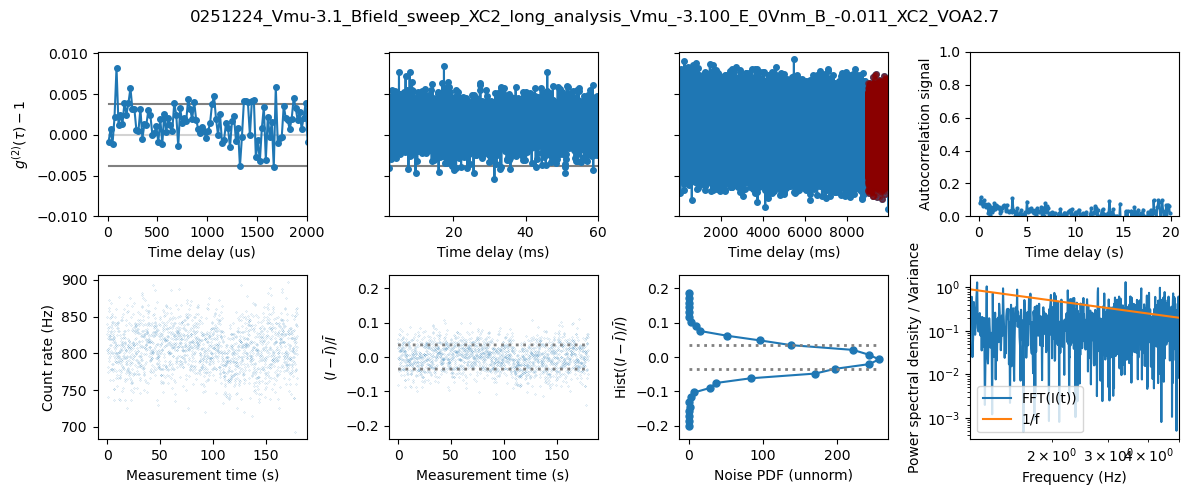

Finished correlating 228.8888 million records in file: Q:\g2_PH300\20251224\20251224_Vmu-3.1_Bfield_sweep_XC2_long_analysis\Vmu_-3.100_E_0Vnm_B_-0.012_XC2_VOA2.7\_chunk0.b
Total 3.081135043 billion coincidences in histogram
Q:\g2_PH300\20251224\20251224_Vmu-3.1_Bfield_sweep_XC2_long_analysis\Vmu_-3.100_E_0Vnm_B_-0.012_XC2_VOA2.7\_chunk0_classical_bins


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_11276\2251475889.py:58: RuntimeWarning: divide by zero encountered in divide
  ac = np.correlate(signal, signal, mode='full') /T_tot/ biased_norm


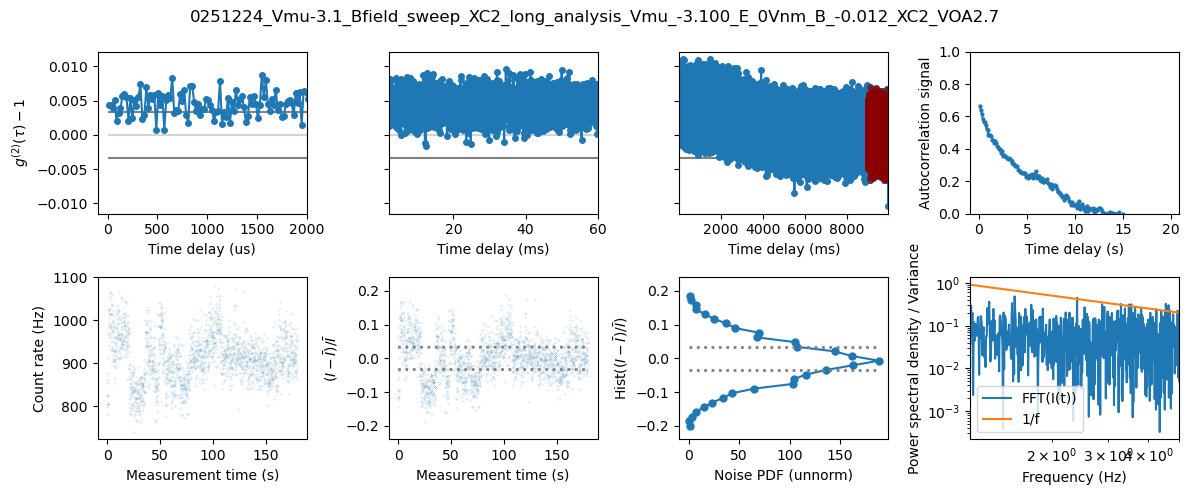

Finished correlating 241.358597 million records in file: Q:\g2_PH300\20251224\20251224_Vmu-3.1_Bfield_sweep_XC2_long_analysis\Vmu_-3.100_E_0Vnm_B_-0.013_XC2_VOA2.7\_chunk0.b
Total 1.601495999 billion coincidences in histogram
Q:\g2_PH300\20251224\20251224_Vmu-3.1_Bfield_sweep_XC2_long_analysis\Vmu_-3.100_E_0Vnm_B_-0.013_XC2_VOA2.7\_chunk0_classical_bins


C:\Users\SSPDs\AppData\Local\Temp\ipykernel_11276\2251475889.py:58: RuntimeWarning: divide by zero encountered in divide
  ac = np.correlate(signal, signal, mode='full') /T_tot/ biased_norm


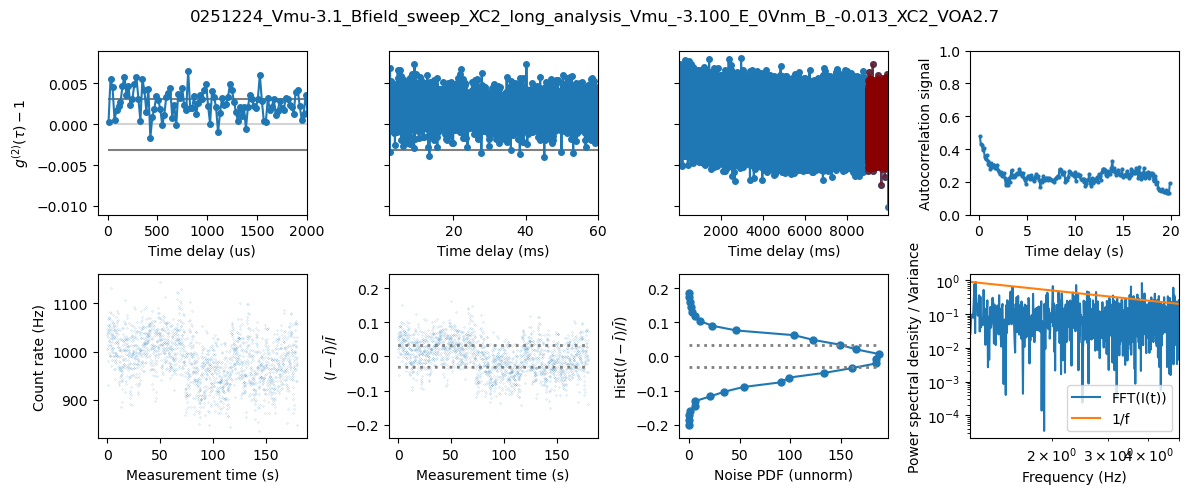

In [16]:

### B SCAN AT Vmu = -3.1, VE = 0
Vmus = [-3.1]
Es   = [0]  
voas = [2.7]
POL = "XC2"

Bs = [-0.011,-0.012,-0.013]
folder =r'Q:\g2_PH300\20251224\20251224_Vmu-3.1_Bfield_sweep_XC2_long_analysis'

# Bs = [0.001]
# folder =r'Q:\g2_PH300\20251224\20251226_Vmu-3.1_Bfield_sweep_XC2_long_analysis'

# folder =r'Q:\g2_PH300\20251224\20251226_Vmu-3.1_Bfield_sweep_'
# folder =r'Q:\g2_PH300\20251228_Vmu-3.1_Bfield_sweep_XC2'

chunk_mins = 3

# init = False
tau_max_us = 10_000_000
for iv in range(len(voas)):
    v = voas[iv]
    for imu in range(len(Vmus)):
        vmu = Vmus[imu]
        # Now initialized, scan negative Es
        for iB in range(len(Bs)):
            name = os.path.join(folder, f"Vmu_{Vmus[imu]:.3f}_E_0Vnm_B_{Bs[iB]:.3f}_{POL}_VOA{v}")
            base = ntpath.join(r'C:\Users\SSPDs\Documents\Offline SSPD Data', name)
            # path = f"_chunk0.b"
            for c in [0]:
                
                path = f"_chunk{c}.b"
                paths = (base, name, path)
                filepath = ntpath.join(base, path)

                for channel in [0]:
                    g2mode = f"A{channel:d}"
                    ### CALCULATE                     
                    
                    # tau, hist, n_records = analysis_cmd.correlate_b_file_highperf(filepath, 
                    tau, hist, n_records = analysis_cmd.correlate_b_file_streaming(filepath,
                                                                chunk_ms=30e3,    
                                                                tau_min_us= 0.2,     # tau max in microseconds
                                                                tau_max_us= tau_max_us,     
                                                                tau_bin_ps= 2e6, #40e3,    # bin width in ps 
                                                                n_workers= 7, 
                                                                mode = g2mode,
                                                                show_progress=True,
                                                                only_do_first_n_chunks=7
                                                                )
                    print(f"Finished correlating {n_records/1e6} million records in file: {filepath}")
                    print(f"Total {np.sum(hist)/1e9} billion coincidences in histogram") 
                    
                    filepath_b = ntpath.join(base, path)

                    tau_bin_ms = 100
                    BASE_RES = 4e-12

                    out_dir, files = analysis_cmd.correlate_b_file_classical(
                        filepath= filepath_b,
                        tau_bin_ms=tau_bin_ms,          
                        chunk_minutes=chunk_mins,    
                        block_records=20_000_000, 
                        include_channels=channel, # none = all channels
                        show_progress=True
                    )

                    #### PLOT
                    g2_ylim = None#(-0.003,0.0045)
                    counts_ylim = None#(200,1300)
                    rebin_factor = 10#30
                    PDF_bins = np.linspace(-0.2,0.2,30)

                    h,t = analyze_all(paths, chunkname=f'_chunk{c}', 
                                      g2mode = g2mode, 
                                      ref_range_s = [0.9*tau_max_us*1e-6,tau_max_us*1e-6], 
                                      include_channel = channel, 
                                      ylims=(g2_ylim, counts_ylim),
                                      rebin_factor = rebin_factor,
                                      PDF_bins = PDF_bins,
                                      savepath=   ntpath.join(folder,f"Analysis collection")# None #None saves to the same directory as the b file
                                      )


# Plotting B-P map in BG


In [ ]:
analysis_cmd.clear_log()
analysis_setup()

------------------ LOG ------------------
[log cleared @ 2026-01-02 12:47:22]


Analysis server reached.
[ANALYSIS - UTC 2026-01-02 11:48:07] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.100_XC2_VOA3.06
[ANALYSIS - UTC 2026-01-02 11:48:11] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.099_XC2_VOA3.06
[ANALYSIS - UTC 2026-01-02 11:48:15] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.098_XC2_VOA3.06
[ANALYSIS - UTC 2026-01-02 11:48:30] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.100_XC2_VOA3.06
[ANALYSIS - UTC 2026-01-02 11:48:32] Reading file with name _chunk0 in mode A0 from folder Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.099_XC2_VOA3.06
[ANALYSIS - UTC 2026-01-02 11:48:34] Reading file with name _chun

In [ ]:
### B SCAN AT Vmu = -3.1, VE = 0
Vmus = [-3.1]
Es   = [0]  
voas = [3.06]
Bs = np.arange(0.1,-0.101,-0.001)
POL = "XC2"
folder =r'Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_'

chunk_mins = 2.5

init = False
tau_max_us = 1_000_000
for iv in range(len(voas)):
    v = voas[iv]
    for imu in range(len(Vmus)):
        vmu = Vmus[imu]
        # Now initialized, scan negative Es
        for iB in range(len(Bs)):
            name = os.path.join(folder+POL, f"Vmu_{Vmus[imu]:.3f}_E_0Vnm_B_{Bs[iB]:.3f}_{POL}_VOA{v}")
            base = ntpath.join(r'C:\Users\SSPDs\Documents\Offline SSPD Data', name)
            # path = f"_chunk0.b"
            for c in [0]:
                
                path = f"_chunk{c}.b"
                paths = (base, name, path)
                filepath = ntpath.join(base, path)

                for channel in [0]:
                    g2mode = f"A{channel:d}"
                    ### CALCULATE                     
                    
                    # tau, hist, n_records = analysis_cmd.correlate_b_file_highperf(filepath, 
                    # tau, hist, n_records = analysis_cmd.correlate_b_file_streaming(filepath,
                    #                                             chunk_ms=10e3,    
                    #                                             tau_min_us= 0.2,     # tau max in microseconds
                    #                                             tau_max_us= tau_max_us,     
                    #                                             tau_bin_ps= 2e6, #40e3,    # bin width in ps 
                    #                                             n_workers= max(1, 8-1), 
                    #                                             mode = g2mode,
                    #                                             show_progress=True)
                    # print(f"Finished correlating {n_records/1e6} million records in file: {filepath}")
                    # print(f"Total {np.sum(hist)/1e9} billion coincidences in histogram") 
                    
                    filepath_b = ntpath.join(base, path)

                    tau_bin_ms = 100
                    BASE_RES = 4e-12

                    # out_dir, files = analysis_cmd.correlate_b_file_classical(
                    #     filepath= filepath_b,
                    #     tau_bin_ms=tau_bin_ms,          
                    #     chunk_minutes=chunk_mins,    
                    #     block_records=20_000_000, 
                    #     include_channels=channel, # none = all channels
                    #     show_progress=True
                    # )

                    
                    #### PLOT
                    # g2_ylim = (-0.02,0.04)
                    # counts_ylim = (0,2200)
                    # rebin_factor = 240
                    # PDF_bins = np.linspace(-0.7,0.7,25)

                    # g2, tau, cr, t = analyze_all(paths, chunkname=f'_chunk{c}', 
                    #                   g2mode = g2mode, 
                    #                   ref_range_s = [0.9*tau_max_us*1e-6,tau_max_us*1e-6], 
                    #                   include_channel = channel, 
                    #                   ylims=(g2_ylim, counts_ylim),
                    #                   rebin_factor = rebin_factor,
                    #                   PDF_bins = PDF_bins,
                    #                   savepath=   ntpath.join(folder+POL,f"Analysis collection")# None #None saves to the same directory as the b file
                    #                   )
                    failed = False
                    try:
                        cr, t = get_crs(paths, chunkname=f'_chunk{c}', include_channel = 0)
                    except:
                        failed = True
                    if not init:
                        cr_all = np.zeros((len(Bs), len(cr)))
                        init = True
                    if not failed:
                        cr_all[iB,:] = cr
                    else:
                        for i in range(len(cr_all[iB,:])):
                            cr_all[iB,i] = np.nan
                    
 
      

Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.100_XC2_VOA3.06\_chunk0_classical_bins
Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.099_XC2_VOA3.06\_chunk0_classical_bins
Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.098_XC2_VOA3.06\_chunk0_classical_bins
Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.097_XC2_VOA3.06\_chunk0_classical_bins
Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.096_XC2_VOA3.06\_chunk0_classical_bins
Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.095_XC2_VOA3.06\_chunk0_classical_bins
Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.094_XC2_VOA3.06\_chunk0_classical_bins
Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.093_XC2_VOA3.06\_chunk0_classical_bins
Q:\g2_PH300\20251231_Vmu-3.1_B_power_sweep_short_XC2\Vmu_-3.100_E_0Vnm_B_0.092_XC2_VOA3.

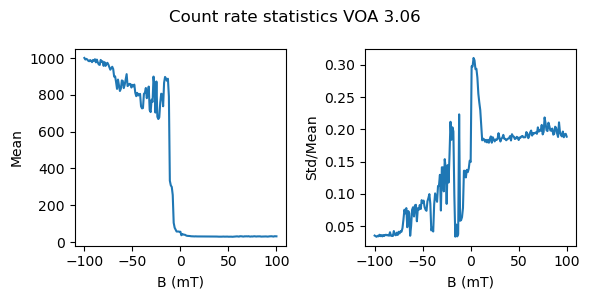

In [58]:
             
save_crs = ntpath.join(ntpath.join(folder+POL,f"Analysis collection"), f"cr_all_voa{v}.npy")
save_t = ntpath.join(ntpath.join(folder+POL,f"Analysis collection"),f"msmt_time_voa{v}.npy")
save_Bs = ntpath.join(ntpath.join(folder+POL,f"Analysis collection"), f"Bs_voa{v}.npy")
np.save(save_crs, cr_all)
np.save(save_t, t)
np.save(save_Bs, Bs)


cr_all = np.load(save_crs)
t = np.load(save_t)
Bs = np.load(save_Bs)
cr_mean = np.mean(cr_all, axis = 1)
cr_std  = np.std(cr_all, axis = 1)
fig, ax = plt.subplots(1,2,figsize = (6,3))
ax[0].plot(Bs*1e3, cr_mean)
ax[1].plot(Bs*1e3, cr_std/cr_mean)
ax[0].set_xlabel("B (mT)")
ax[1].set_xlabel("B (mT)")
ax[1].set_ylabel("Std/Mean")
ax[0].set_ylabel("Mean")
fig.suptitle(f"Count rate statistics VOA {v}")
plt.tight_layout()
plt.savefig(ntpath.join(ntpath.join(folder+POL,f"Analysis collection"),f"cr_statistics_voa{v}.png"),dpi = 250)